In [9]:
# Assignment 8    Implement Lasso and Ridge Regression

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

data = load_diabetes()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Features:", data.feature_names)

Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


In [2]:
models = {
    "Linear": LinearRegression(),
    "Ridge": Ridge(alpha=1),
    "Lasso": Lasso(alpha=1)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(f"{name:7s} MSE = {mean_squared_error(y_test, pred):.2f}   R2 = {r2_score(y_test, pred):.3f}")

Linear  MSE = 2900.19   R2 = 0.453
Ridge   MSE = 3077.42   R2 = 0.419
Lasso   MSE = 3403.58   R2 = 0.358


     Linear   Ridge   Lasso
age   37.90   45.37    0.00
sex -241.96  -76.67   -0.00
bmi  542.43  291.34  413.43
bp   347.70  199.00   34.83
s1  -931.49   -0.53    0.00
s2   518.06  -28.58    0.00
s3   163.42 -144.51   -0.00
s4   275.32  119.26    0.00
s5   736.20  230.22  258.15
s6    48.67  112.15    0.00


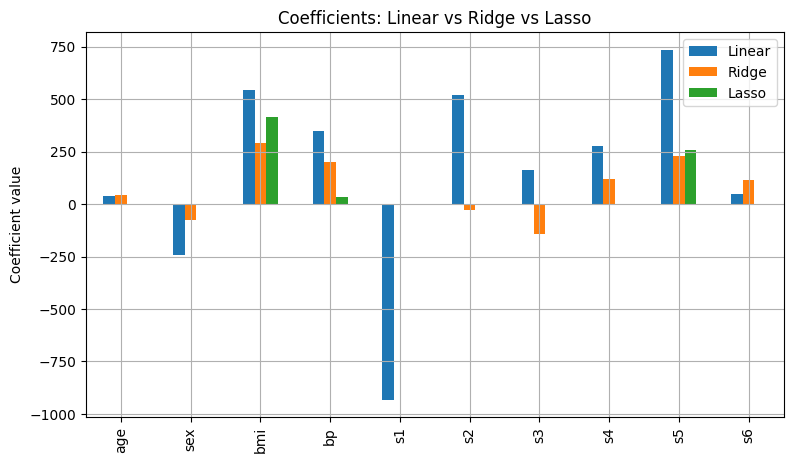

In [3]:
coef = pd.DataFrame({name: m.coef_ for name, m in models.items()},
                    index=data.feature_names)
print(coef.round(2))

coef.plot(kind='bar', figsize=(9, 5))
plt.title("Coefficients: Linear vs Ridge vs Lasso")
plt.ylabel("Coefficient value")
plt.grid(True)
plt.show()

In [11]:
# Ridge Regression adds a penalty based on the square of the coefficients.
# Lasso Regression adds a penalty based on the absolute values of coefficients.
# Ridge and Lasso give similar or slightly better test error than plain Linear Regression, so regularization does not hurt and can help generalization.
# Ridge coefficients are smaller than Linear coefficients. The penalty shrinks them, but none become exactly 0.
# Lasso sets some coefficients to exactly 0 (for example age or some of the s-features), so it selects only the important features.
# bmi and s5 (and bp) have the largest coefficients in all three models, so they are the most important features for predicting the target.
# A larger alpha means more shrinkage. Too large an alpha underfits (high bias), and too small an alpha behaves like plain linear regression.